In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint, CSVLogger

import random
from PIL import Image

In [2]:
for root, dirs, files in os.walk('/kaggle/input'):
    level = root.replace('/kaggle/input', '').count(os.sep)

    if level <= 3:
        print(root)
        print("Folders:", dirs[:10])
        print("Images/files:", len(files))
        print("-" * 40)

/kaggle/input
Folders: ['datasets']
Images/files: 0
----------------------------------------
/kaggle/input/datasets
Folders: ['mosabbirahmed']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed
Folders: ['intel-image-classification-no-splits']
Images/files: 0
----------------------------------------
/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits
Folders: ['intel_dataset']
Images/files: 0
----------------------------------------


In [3]:
data_dir='/kaggle/input/datasets/mosabbirahmed/intel-image-classification-no-splits/intel_dataset'

for item in sorted(os.listdir(data_dir)):
    path=os.path.join(data_dir,item)

    if os.path.isdir(path):
        print(f'Folder: {item}')
        print('Number of items:', len(os.listdir(path)))
        print('Sample items:', os.listdir(path)[:5])
        print('-' * 40)
    else:
        print(f'File: {item}')

Folder: buildings
Number of items: 2609
Sample items: ['10006.jpg', '1001.jpg', '10018.jpg', '10029.jpg', '10032.jpg']
----------------------------------------
Folder: forest
Number of items: 2745
Sample items: ['10007.jpg', '10010.jpg', '10020.jpg', '10030.jpg', '10037.jpg']
----------------------------------------
Folder: glacier
Number of items: 2874
Sample items: ['10.jpg', '100.jpg', '10003.jpg', '10009.jpg', '10011.jpg']
----------------------------------------
Folder: mountain
Number of items: 3027
Sample items: ['10000.jpg', '10001.jpg', '10002.jpg', '10008.jpg', '10023.jpg']
----------------------------------------
Folder: sea
Number of items: 2762
Sample items: ['10016.jpg', '10041.jpg', '10053.jpg', '10061.jpg', '10068.jpg']
----------------------------------------
Folder: street
Number of items: 2883
Sample items: ['1000.jpg', '10015.jpg', '10019.jpg', '10022.jpg', '10036.jpg']
----------------------------------------


In [4]:
#from collections import Counter
classes=sorted([
    name for name in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir,name))
])
print('calsses: ',classes)

image_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

counts = {}

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    images=[
      f for f in os.listdir(class_path)
      if f.lower().endswith(image_extensions)
    and os.path.isfile(os.path.join(class_path,f))
  ]
    counts[class_name]=len(images)

print("\nNumber of images per class:")
for name, count in counts.items():
    print(f"{name}: {count}")

print("\nTotal images:", sum(counts.values()))



calsses:  ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Number of images per class:
buildings: 2609
forest: 2745
glacier: 2874
mountain: 3027
sea: 2762
street: 2883

Total images: 16900


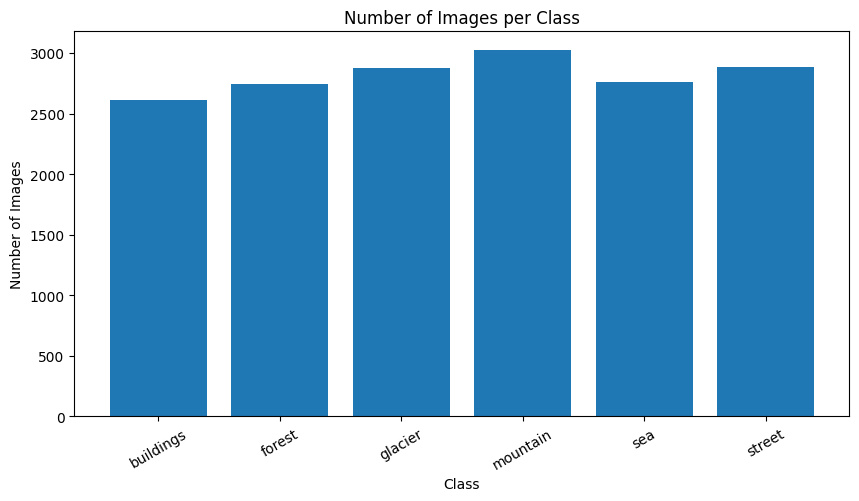

In [5]:
plt.figure(figsize=(10, 5))

plt.bar(counts.keys(), counts.values())
plt.title("Number of Images per Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=30)
plt.show()

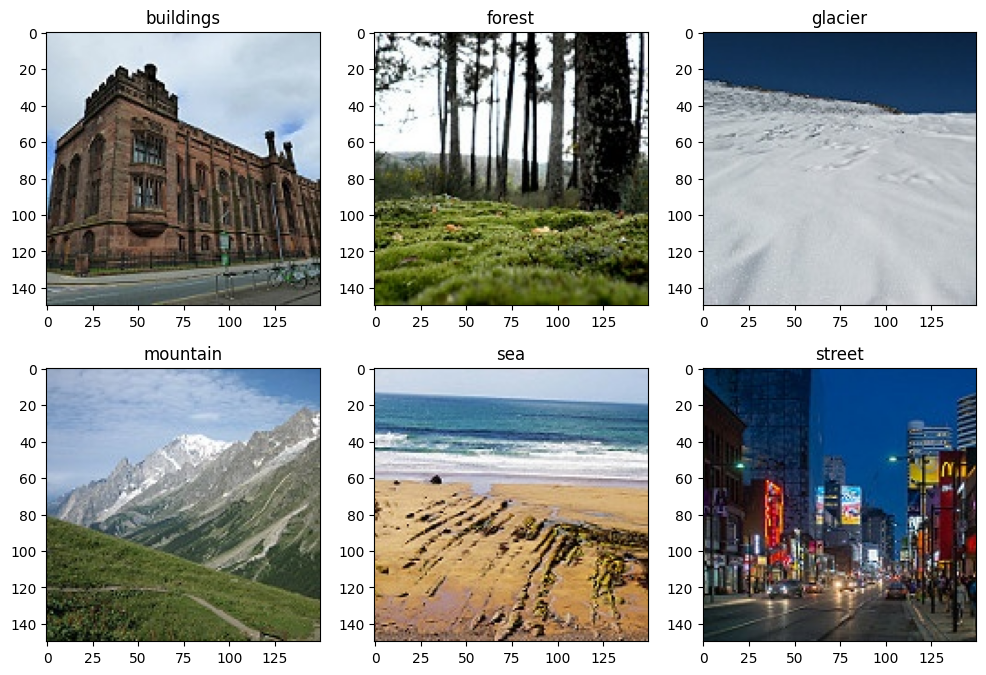

In [6]:
plt.figure(figsize=(12,8))

for i,class_name in enumerate(classes[:6]):
    class_path=os.path.join(data_dir,class_name)

    images=[
        f for f in os.listdir(class_path)
        if f.lower().endswith(image_extensions)
        and os.path.isfile(os.path.join(class_path,f))
    ]

    if not images:
        continue

    image_name=random.choice(images)
    image_path=os.path.join(class_path,image_name)

    img=Image.open(image_path).convert("RGB")

    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(class_name)

In [7]:
filepaths=[]
labels=[]

for class_name in classes:
    class_path=os.path.join(data_dir,class_name)

    for file in os.listdir(class_path):
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            filepaths.append(os.path.join(class_path,file))
            labels.append(class_name)

df=pd.DataFrame({
    'filepath':filepaths,
    'label':labels
})

train_df,temp_df=train_test_split(df,test_size=.20,random_state=42,stratify=df['label'])

val_df,test_df=train_test_split(temp_df,test_size=.50,random_state=42,stratify=temp_df['label'])

print("Train images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("\nTrain class distribution:")
print(train_df['label'].value_counts().sort_index())


Train images: 13520
Validation images: 1690
Test images: 1690

Train class distribution:
label
buildings    2087
forest       2196
glacier      2299
mountain     2422
sea          2210
street       2306
Name: count, dtype: int64


In [8]:
img_size=(150,150)
batch_size=32

train_datagen=ImageDataGenerator(
    rescale=1./255,
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

eval_datagen=ImageDataGenerator(rescale=1./255)

train_gen=train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=True,
    seed=42
    
)

val_gen=eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)
test_gen = eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col='filepath',
    y_col='label',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    shuffle=False
)


print("Class indices:", train_gen.class_indices)

Found 13520 validated image filenames belonging to 6 classes.
Found 1690 validated image filenames belonging to 6 classes.
Found 1690 validated image filenames belonging to 6 classes.
Class indices: {'buildings': 0, 'forest': 1, 'glacier': 2, 'mountain': 3, 'sea': 4, 'street': 5}


In [9]:
model=models.Sequential([
    layers.Input(shape=(150,150,3)),

    layers.Conv2D(32,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128,(3,3),padding='same',activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),

    layers.Dense(128,activation='relu'),
    layers.Dropout(0.5),

    layers.Dense(len(classes),activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='categorical_crossentropy'
    ,metrics=['accuracy']
)

model.summary()

I0000 00:00:1793463048.743058      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793463048.747156      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,402,566 (20.61 MB)

 Trainable params: 5,402,566 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
callbacks = [
    EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        filepath='best_model.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    ),
    CSVLogger(
        filename='training_log.csv',
        separator=',',
        append=False
    ),

    ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history=model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=20,
    callbacks=callbacks
)

Epoch 1/20


2026-10-31 16:11:00.546985: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 16:11:00.694798: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


  1/423 ━━━━━━━━━━━━━━━━━━━━ 1:01:52 9s/step - accuracy: 0.0938 - loss: 1.7923

I0000 00:00:1793463063.302297      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


 91/423 ━━━━━━━━━━━━━━━━━━━━ 8:00 1s/step - accuracy: 0.3425 - loss: 1.6323

2026-10-31 16:13:15.383716: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-31 16:13:15.527815: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


423/423 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4725 - loss: 1.3269
Epoch 1: val_loss improved from None to 0.78249, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
423/423 ━━━━━━━━━━━━━━━━━━━━ 678s 2s/step - accuracy: 0.5577 - loss: 1.1284 - val_accuracy: 0.6899 - val_loss: 0.7825 - learning_rate: 0.0010
Epoch 2/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.6594 - loss: 0.8909
Epoch 2: val_loss improved from 0.78249 to 0.62966, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
423/423 ━━━━━━━━━━━━━━━━━━━━ 84s 198ms/step - accuracy: 0.6751 - loss: 0.8649 - val_accuracy: 0.7740 - val_loss: 0.6297 - learning_rate: 0.0010
Epoch 3/20
423/423 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step - accuracy: 0.7158 - loss: 0.7745
Epoch 3: val_loss improved from 0.62966 to 0.59972, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
423/423 ━━━━━━━━━━━━━━━━━━━━ 87s 206ms/step - accuracy: 

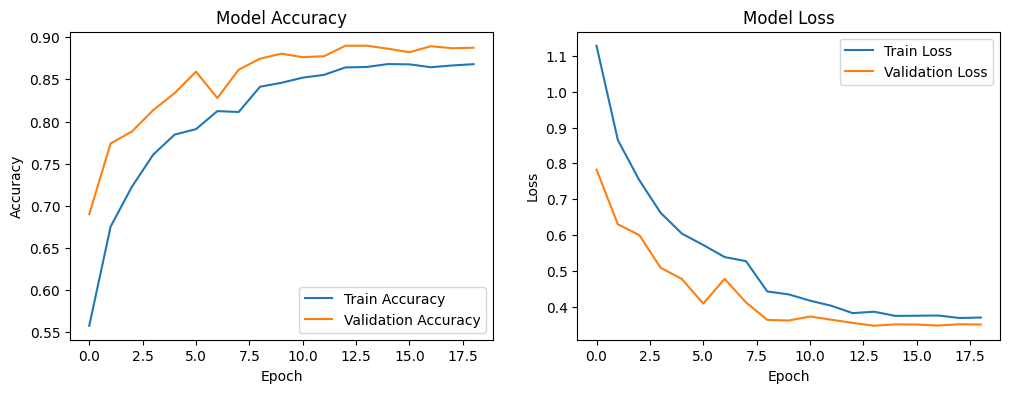

In [11]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

In [12]:
test_loss, test_acc = model.evaluate(test_gen)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc * 100:.2f}%")

test_gen.reset()
predictions = model.predict(test_gen)

y_pred = np.argmax(predictions, axis=1)
y_true = test_gen.classes

class_names = list(test_gen.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

53/53 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8899 - loss: 0.3465
Test Loss: 0.3465
Test Accuracy: 88.99%
53/53 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step
              precision    recall  f1-score   support

   buildings       0.85      0.90      0.88       261
      forest       0.96      0.99      0.97       275
     glacier       0.89      0.82      0.86       287
    mountain       0.85      0.87      0.86       303
         sea       0.88      0.88      0.88       276
      street       0.90      0.89      0.89       288

    accuracy                           0.89      1690
   macro avg       0.89      0.89      0.89      1690
weighted avg       0.89      0.89      0.89      1690



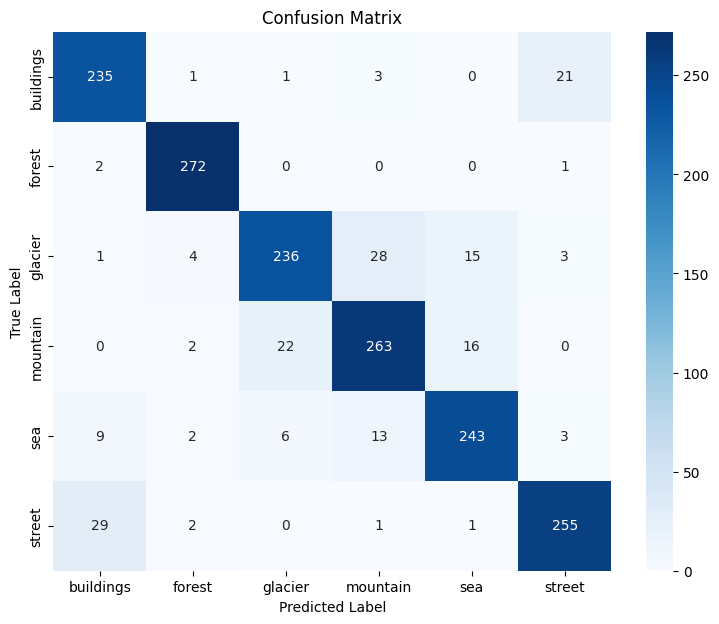

In [13]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

In [14]:
model.save('/kaggle/working/intel_image_classifier.keras')

print("Model saved successfully!")

Model saved successfully!
